In [93]:
from sys import displayhook

import networkx as nx
import matplotlib.pyplot as plt
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np

csv_path = os.path.join("data", "compras_ecommerce.csv")
df = pd.read_csv(csv_path)

print(len(df))

display(df.head())


6858


,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


In [94]:
df_copy = df.copy()

# Se eliminan valores nulos
df_copy = df_copy.dropna()

print(len(df_copy))

df_copy.head()

6708


,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


In [95]:
df_copy['Producto'] = df_copy['Producto'].apply(lambda x : str(x).upper())

df_copy

,ID_Transaccion,Producto
0,TKT-00181,TECLADO MECÁNICO RGB
1,TKT-01162,"MONITOR 27"" 144HZ"
2,TKT-00840,SILLA GAMER ERGONÓMICA
3,TKT-01734,SILLA GAMER ERGONÓMICA
4,TKT-01899,MOUSEPAD XL
...,...,...
6853,TKT-01463,SILLA GAMER ERGONÓMICA
6854,TKT-02012,MOUSEPAD XL
6855,TKT-02023,SILLA GAMER ERGONÓMICA
6856,TKT-02086,MICRÓFONO DE CONDENSADOR


In [96]:
df_copy = df_copy[df_copy['ID_Transaccion'] != 'ERR_TIMEOUT']
print(len(df_copy))
df_copy

6629


,ID_Transaccion,Producto
0,TKT-00181,TECLADO MECÁNICO RGB
1,TKT-01162,"MONITOR 27"" 144HZ"
2,TKT-00840,SILLA GAMER ERGONÓMICA
3,TKT-01734,SILLA GAMER ERGONÓMICA
4,TKT-01899,MOUSEPAD XL
...,...,...
6853,TKT-01463,SILLA GAMER ERGONÓMICA
6854,TKT-02012,MOUSEPAD XL
6855,TKT-02023,SILLA GAMER ERGONÓMICA
6856,TKT-02086,MICRÓFONO DE CONDENSADOR


In [97]:
df_copy = df_copy.drop_duplicates(subset=['ID_Transaccion', 'Producto'], keep='last')

print(len(df_copy))
df_copy

6258


,ID_Transaccion,Producto
0,TKT-00181,TECLADO MECÁNICO RGB
1,TKT-01162,"MONITOR 27"" 144HZ"
2,TKT-00840,SILLA GAMER ERGONÓMICA
3,TKT-01734,SILLA GAMER ERGONÓMICA
4,TKT-01899,MOUSEPAD XL
...,...,...
6853,TKT-01463,SILLA GAMER ERGONÓMICA
6854,TKT-02012,MOUSEPAD XL
6855,TKT-02023,SILLA GAMER ERGONÓMICA
6856,TKT-02086,MICRÓFONO DE CONDENSADOR


In [98]:
df_copy_2 = pd.merge(df_copy, df_copy, on='ID_Transaccion', how='inner')
print(len(df_copy_2))

17766


In [99]:
df_copy_2 = df_copy_2[df_copy_2['Producto_x'] != df_copy_2['Producto_y']]
print(len(df_copy_2))
df_copy_2

11508


,ID_Transaccion,Producto_x,Producto_y
1,TKT-00181,TECLADO MECÁNICO RGB,"MONITOR 27"" 144HZ"
2,TKT-00181,TECLADO MECÁNICO RGB,MOUSEPAD XL
3,TKT-00181,TECLADO MECÁNICO RGB,SILLA GAMER ERGONÓMICA
5,TKT-01162,"MONITOR 27"" 144HZ",MOUSEPAD XL
6,TKT-01162,"MONITOR 27"" 144HZ",SILLA GAMER ERGONÓMICA
...,...,...,...
17759,TKT-02086,MICRÓFONO DE CONDENSADOR,WEBCAM 1080P
17760,TKT-02086,MICRÓFONO DE CONDENSADOR,"MONITOR 27"" 144HZ"
17762,TKT-00335,AUDÍFONOS BLUETOOTH,WEBCAM 1080P
17763,TKT-00335,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO


In [100]:
df_copy_2[['Producto_x', 'Producto_y']] = np.sort(
    df_copy_2[['Producto_x', 'Producto_y']].values, axis=1
)

df_copy_2 = df_copy_2.drop_duplicates(subset=['ID_Transaccion', 'Producto_x', 'Producto_y'], keep='last')
print(len(df_copy_2))
df_copy_2

5754


,ID_Transaccion,Producto_x,Producto_y
217,TKT-02167,"MONITOR 27"" 144HZ",TECLADO MECÁNICO RGB
268,TKT-01961,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB
347,TKT-01912,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB
375,TKT-00956,LAPTOP PRO 15,MOUSE INALÁMBRICO
421,TKT-02139,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO
...,...,...,...
17759,TKT-02086,MICRÓFONO DE CONDENSADOR,WEBCAM 1080P
17760,TKT-02086,MICRÓFONO DE CONDENSADOR,"MONITOR 27"" 144HZ"
17762,TKT-00335,AUDÍFONOS BLUETOOTH,WEBCAM 1080P
17763,TKT-00335,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO


In [101]:
combinaciones = df_copy_2.groupby(['Producto_x', 'Producto_y']).size().reset_index(name='Peso')

combinaciones

,Producto_x,Producto_y,Peso
0,AUDÍFONOS BLUETOOTH,CABLE HDMI 2.1,21
1,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341
2,AUDÍFONOS BLUETOOTH,MICRÓFONO DE CONDENSADOR,21
3,AUDÍFONOS BLUETOOTH,"MONITOR 27"" 144HZ",20
4,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO,334
5,AUDÍFONOS BLUETOOTH,MOUSEPAD XL,23
6,AUDÍFONOS BLUETOOTH,SILLA GAMER ERGONÓMICA,17
7,AUDÍFONOS BLUETOOTH,TECLADO MECÁNICO RGB,26
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
9,CABLE HDMI 2.1,LAPTOP PRO 15,25


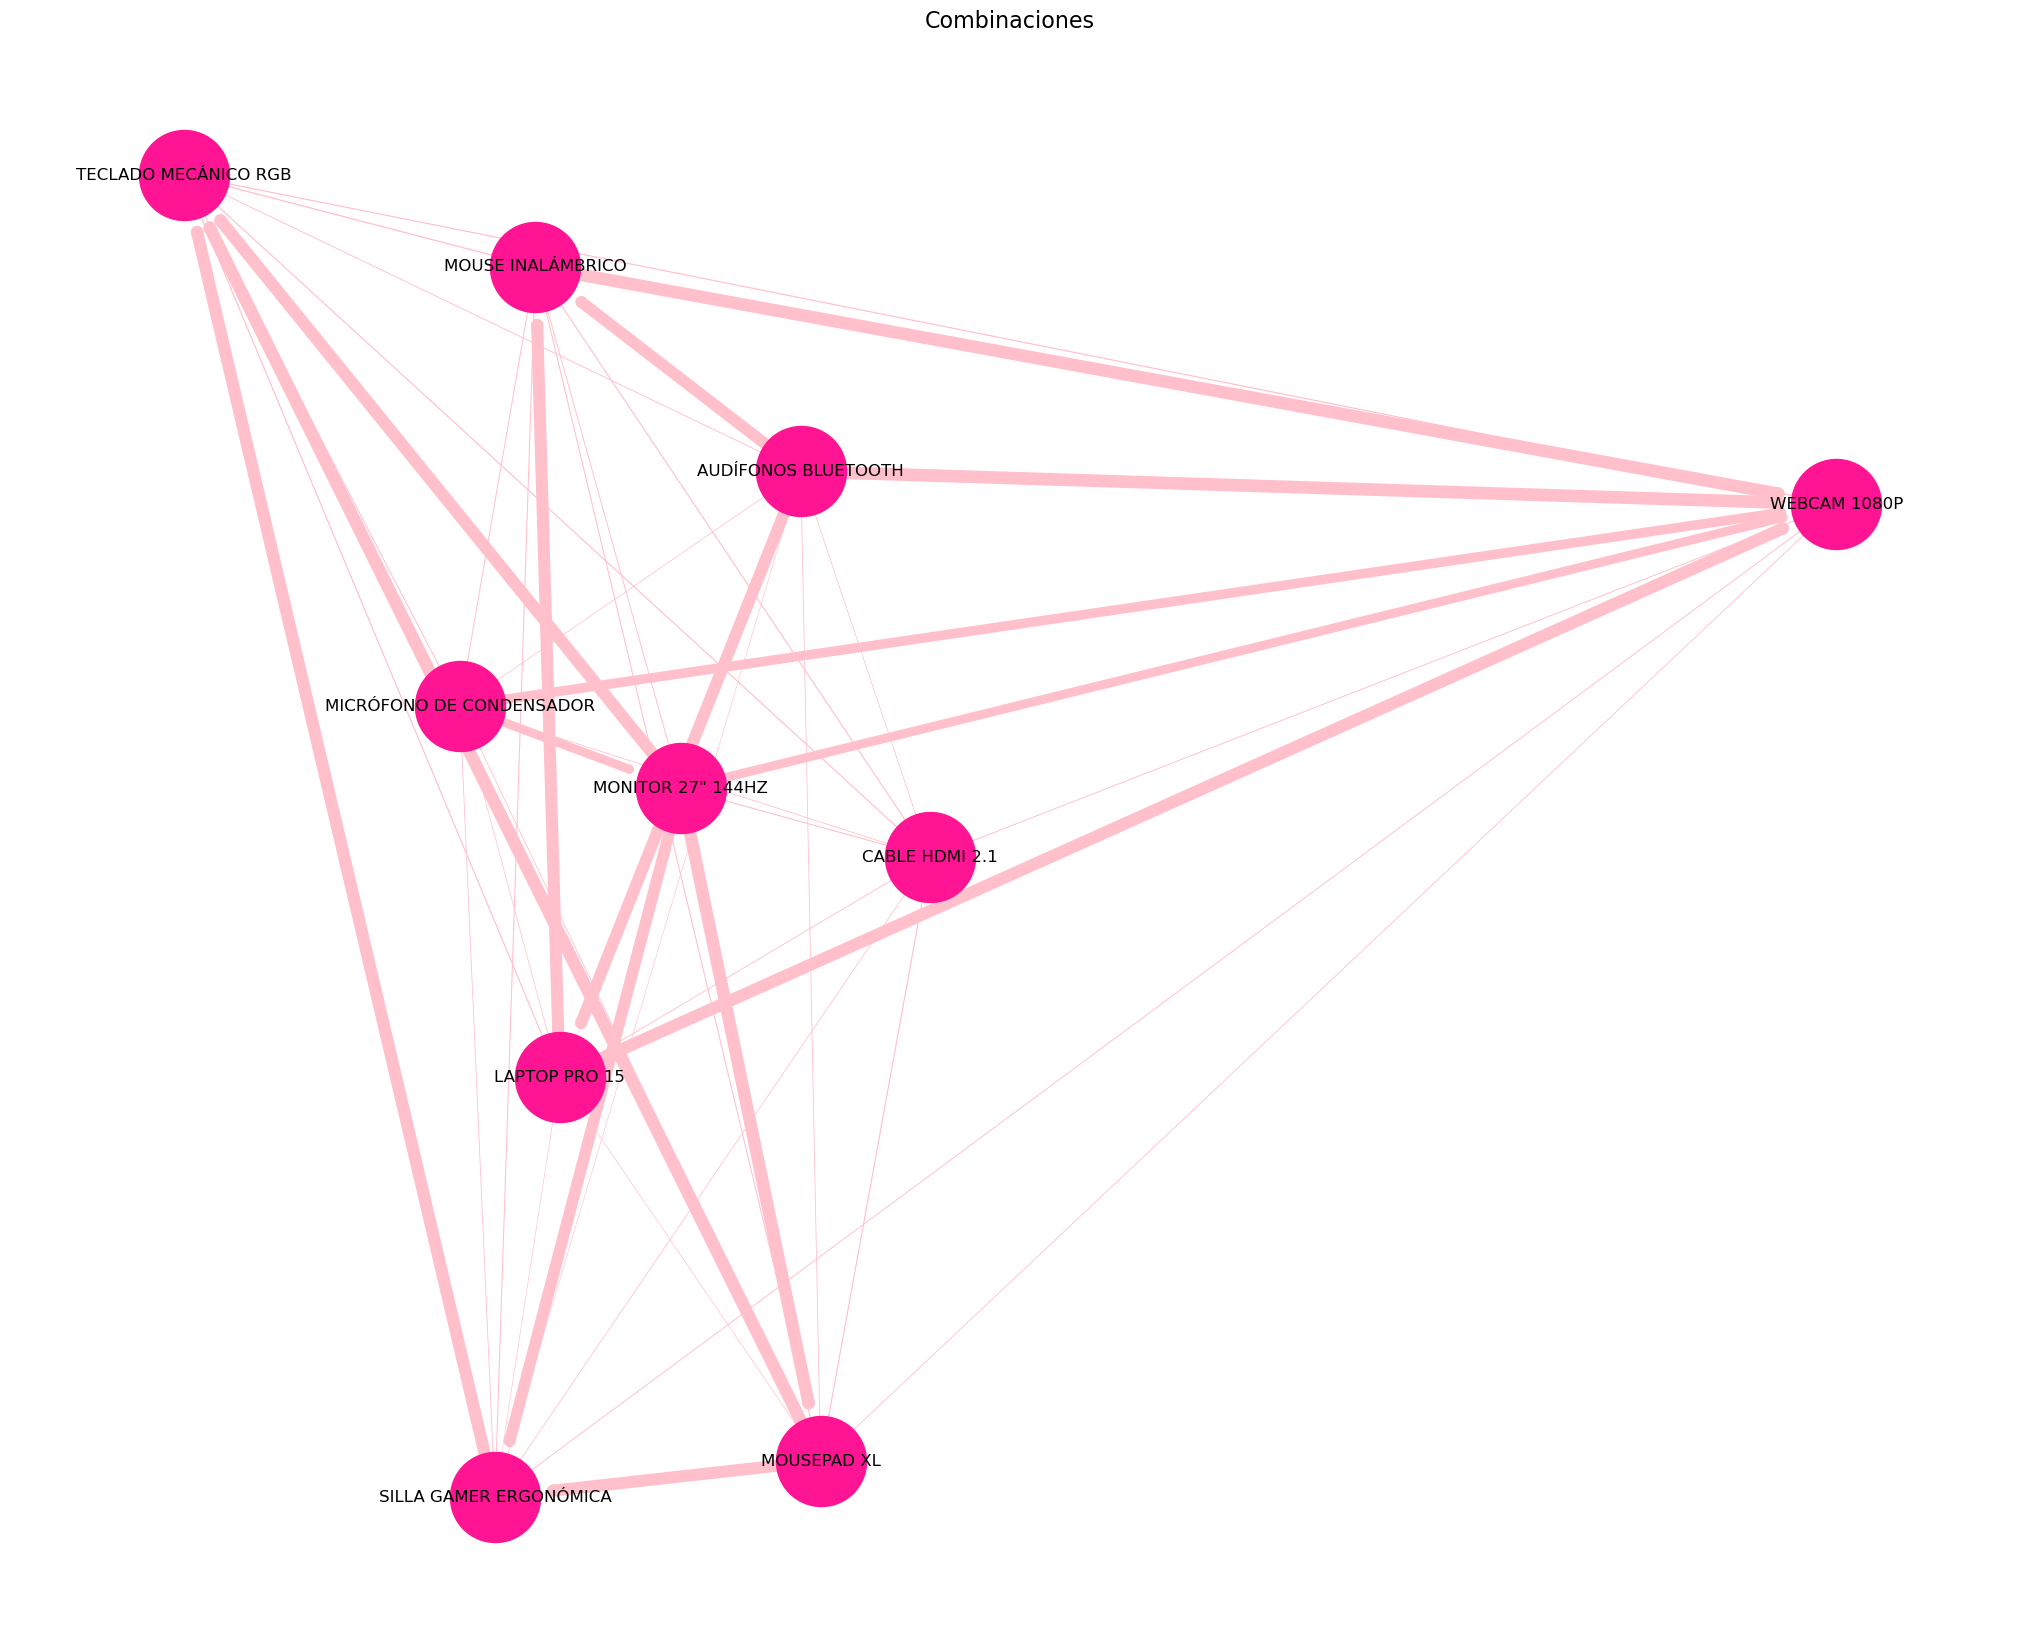

In [114]:
G_comb = nx.from_pandas_edgelist(combinaciones, source='Producto_x', target='Producto_y', edge_attr='Peso', create_using=nx.DiGraph())


plt.figure(figsize=(20,16))
pos = nx.spring_layout(G_comb, seed=42)
pesos = [d['Peso']/40 for (u, v, d) in G_comb.edges(data=True)]
nx.draw(G_comb, pos, with_labels=True, node_color='deeppink', node_size=4200, font_color='black', width=pesos, edge_color='pink', arrowsize=1)
plt.title('Combinaciones', fontsize=16)
plt.show()


In [103]:
nx.degree_centrality(G_comb)

{'AUDÍFONOS BLUETOOTH': 1.0,
 'CABLE HDMI 2.1': 1.0,
 'LAPTOP PRO 15': 1.0,
 'MICRÓFONO DE CONDENSADOR': 1.0,
 'MONITOR 27" 144HZ': 1.0,
 'MOUSE INALÁMBRICO': 1.0,
 'MOUSEPAD XL': 1.0,
 'SILLA GAMER ERGONÓMICA': 1.0,
 'TECLADO MECÁNICO RGB': 1.0,
 'WEBCAM 1080P': 1.0}

# Respuesta
Se debe de recomendar el mousepad XL, para maximizar la probabilidad de venta conjunta, cuando un cliente excoge el teclado mecanico RGB.